In [1]:
import pandas as pd

In [2]:
prices = pd.read_excel("../data/RNGWHHDd.xls") # this command reads the first sheet in the excel file by default

In [3]:
prices.head() # displays the first 5 rows of the data frame so we can quickly get an idea what's in the excel file

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5
0,NaN,Workbook Contents,NaN,NaN,NaN,NaN
1,NaN,Henry Hub Natural Gas Spot Price (Dollars per ...,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,Click worksheet name or tab at bottom for data,NaN,NaN,NaN,NaN
4,NaN,Worksheet Name,Description,# Of Series,Frequency,Latest Data for


In [4]:
pd.ExcelFile("../data/RNGWHHDd.xls").sheet_names # pd.ExcelFile(...) tells pandas to treat the file as an Excel workbook rather than one sheet

['Contents', 'Data 1']

In [5]:
prices = pd.read_excel("../data/RNGWHHDd.xls", sheet_name="Data 1") # now that we know the data we want to manipulate is stored in sheet "Data 1"

In [6]:
prices.head()

,Back to Contents,Data 1: Henry Hub Natural Gas Spot Price (Dollars per Million Btu)
0,Sourcekey,RNGWHHD
1,Date,Henry Hub Natural Gas Spot Price (Dollars per ...
2,1997-01-07 00:00:00,3.82
3,1997-01-08 00:00:00,3.8
4,1997-01-09 00:00:00,3.61


In [7]:
prices.shape # how big is this data frame (rows,columns)?

(5700, 2)

In [8]:
prices.info() # return generic info about the data frame i.e. column names, non-missing values, and the data type of each column

<class 'pandas.DataFrame'>
RangeIndex: 5700 entries, 0 to 5699
Data columns (total 2 columns):
 #   Column                                                              Non-Null Count  Dtype 
---  ------                                                              --------------  ----- 
 0   Back to Contents                                                    5700 non-null   object
 1   Data 1: Henry Hub Natural Gas Spot Price (Dollars per Million Btu)  5699 non-null   object
dtypes: object(2)
memory usage: 89.2+ KB


In [9]:
prices.tail() # displays the last 5 rows of the data frame so we can quickly get an idea of how late the data goes until

,Back to Contents,Data 1: Henry Hub Natural Gas Spot Price (Dollars per Million Btu)
5695,2026-09-23 00:00:00,3.06
5696,2026-09-24 00:00:00,3
5697,2026-09-25 00:00:00,3.21
5698,2026-09-28 00:00:00,3.13
5699,2026-09-29 00:00:00,3.18


In [10]:
prices = pd.read_excel("../data/RNGWHHDd.xls",sheet_name="Data 1",header=2) # with header=2 we're actually saying "Don't treat Excel's first row as the column headers. The actual headers are on the third row."

In [11]:
prices.head()

,Date,Henry Hub Natural Gas Spot Price (Dollars per Million Btu)
0,1997-01-07,3.82
1,1997-01-08,3.80
2,1997-01-09,3.61
3,1997-01-10,3.92
4,1997-01-13,4.00


In [12]:
prices.info()

# the data types of each column should change from "objects" (which means it's a mixture of text and different data types) to "datetime64[us]" and "float64" - this is nice because now the data types in each column are consistent

<class 'pandas.DataFrame'>
RangeIndex: 5698 entries, 0 to 5697
Data columns (total 2 columns):
 #   Column                                                      Non-Null Count  Dtype         
---  ------                                                      --------------  -----         
 0   Date                                                        5698 non-null   datetime64[us]
 1   Henry Hub Natural Gas Spot Price (Dollars per Million Btu)  5697 non-null   float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 89.2 KB


In [13]:
prices[prices["Henry Hub Natural Gas Spot Price (Dollars per Million Btu)"].isna()]

# since there are 5698 entries for the date column and 5697 for the price column, one of the prices are missing so this command allows us to find where that NaN occurs

,Date,Henry Hub Natural Gas Spot Price (Dollars per Million Btu)
3516,2018-01-05,NaN


In [14]:
prices[(prices["Date"] >= "2018-01-02") & (prices["Date"] <= "2018-01-10")]

# this allows us to look at some data before and after the date of the missing price - apparently there was a major-cold weather event around the beginning of January which produced a 359 Bcf storage withdrawal (record at the time), so let's leave it as is
# pandas will ignore the NaN rather than treating it as $0 so it's okay to keep the row

,Date,Henry Hub Natural Gas Spot Price (Dollars per Million Btu)
3513,2018-01-02,6.24
3514,2018-01-03,6.24
3515,2018-01-04,4.65
3516,2018-01-05,NaN
3517,2018-01-08,2.89
3518,2018-01-09,2.93
3519,2018-01-10,3.16


In [15]:
prices = prices.rename(columns={"Henry Hub Natural Gas Spot Price (Dollars per Million Btu)": "price"}) # the price header is too long so we're shortening it

In [16]:
prices.head()

,Date,price
0,1997-01-07,3.82
1,1997-01-08,3.80
2,1997-01-09,3.61
3,1997-01-10,3.92
4,1997-01-13,4.00


In [17]:
prices["price"].describe() # this one command gives you a quick stats for the price column

count    5697.000000
mean        3.876447
std         2.071015
min         1.210000
25%         2.620000
50%         3.200000
75%         4.420000
max        30.720000
Name: price, dtype: float64

In [18]:
prices["price"].max() # what was the highest Henry Hub price in the entire dataset?

np.float64(30.72)

In [19]:
prices.loc[prices["price"].idxmax()] # on what date did that max price occur?

Date     2026-01-23 00:00:00
price                  30.72
Name: 5526, dtype: object

In [20]:
import matplotlib.pyplot as plt # import visualization library

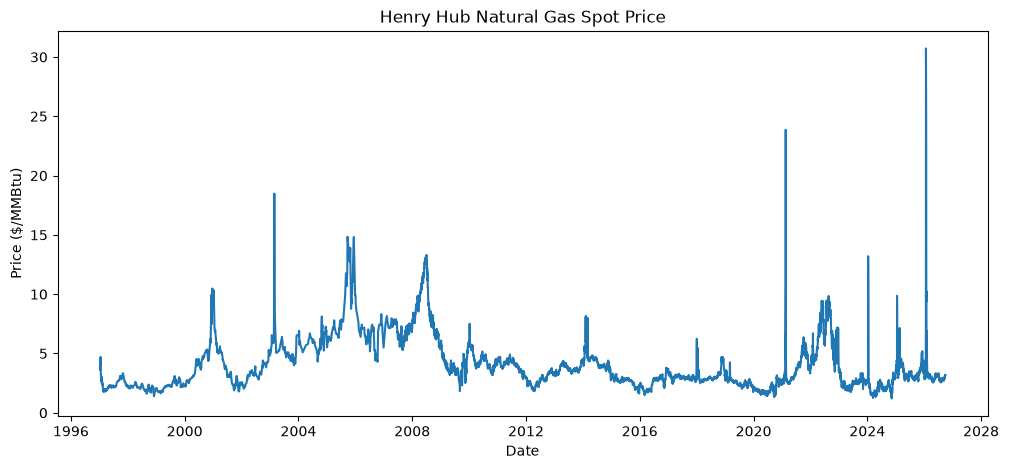

In [21]:
# create the chart

plt.figure(figsize=(12, 5)) # this just formats the aspect ratio of the chart

plt.plot(prices["Date"], prices["price"]) # (x-axis data,y-axis data) format

plt.title("Henry Hub Natural Gas Spot Price")
plt.xlabel("Date")
plt.ylabel("Price ($/MMBtu)")

plt.show()

In [22]:
# we want to try to make a new variable called monthly_prices which will store the monthly average prices
# for questions like "how do U.S. production, LNG exports, and storage relate to Henry Hub prices?", monthly data will be useful because lots of data are available on monthly intervals

monthly_prices = (
    prices
    .set_index("Date") # makes date the index
    .resample("ME") # groups by month instead of daily, "ME" means month end
    .mean() # calculates each month's average price
    .reset_index() # turns the dates back into a regular column
)

monthly_prices.head()

,Date,price
0,1997-01-31,3.555625
1,1997-02-28,2.199333
2,1997-03-31,1.897059
3,1997-04-30,2.032727
4,1997-05-31,2.245263


In [23]:
monthly_prices.shape

(357, 2)

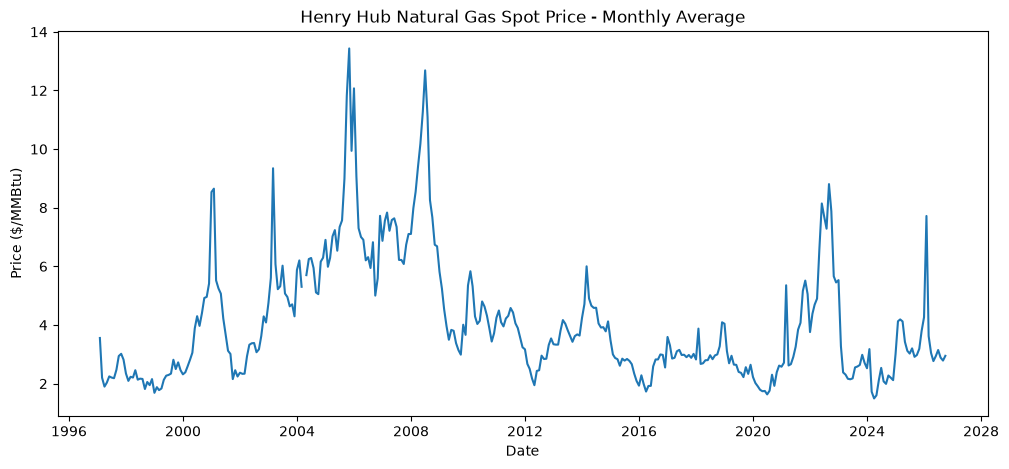

In [24]:
# create a monthly average prices chart

plt.figure(figsize=(12, 5)) # this just formats the aspect ratio of the chart

plt.plot(monthly_prices["Date"], monthly_prices["price"]) # (x-axis data,y-axis data) format

plt.title("Henry Hub Natural Gas Spot Price - Monthly Average")
plt.xlabel("Date")
plt.ylabel("Price ($/MMBtu)")

plt.show()

In [25]:
# export monthly Henry Hub data to newly created folder under "data" called "processed"
# .to_csv() takes a data frame and generates a csv file under the folder you choose
# index=False tells pandas not to write the DataFrame's row numbers (0, 1, 2, 3...) into the CSV - those numbers aren't actual market data, so we don't need them
monthly_prices.to_csv("../data/processed/henry_hub_monthly.csv",index=False)